# From an OMOP CDM to ICU labels and a PyPOTS model

This notebook goes from an OMOP CDM to a trained classifier. ehrdata reads the ICU stays of the CDM into an `EHRData` of hourly variables, ehrapy derives the SOFA score, Sepsis-3 and the KDIGO stage of acute kidney injury from them, and ehrapy's `ml` module trains a PyPOTS model that predicts acute kidney injury from the first 24 hours of a stay.

Its sections follow ehrapy's tutorial `icu_labels.ipynb`, which reads the OHDSI conversion of the same demo, with fewer inputs. It extends ehrdata's tutorial `omop_ml.ipynb` with ehrapy's ICU label tools and with the concept sets of the cohort builder of this repository (`../build_cohort.py`). The CDM is the MIMIC-IV demo of 100 patients, converted to OMOP by `omop_etl`. Outputs show counts, metrics and plots of a few stays of the open demo.

The stored outputs contain information from the MIMIC-IV Clinical Database Demo v2.2 (Johnson et al., PhysioNet 2023, [doi:10.13026/dp1f-ex47](https://doi.org/10.13026/dp1f-ex47)), which is made available under the [Open Database License (ODbL) v1.0](https://opendatacommons.org/licenses/odbl/1-0/).

## Environment setup

In [1]:
import os
import sys
import warnings

os.environ["SCIPY_ARRAY_API"] = "1"  # PyPOTS needs it for scipy
warnings.filterwarnings("ignore")

import duckdb
import ehrapy as ep
import ehrdata as ed
import holoviews as hv
import numpy as np
import pandas as pd
import torch
from pypots.nn.modules.grud import BackboneGRUD

warnings.filterwarnings("ignore")  # again, since statsmodels and bokeh set filters of their own when imported

# The OMOP CDM: a folder with a Parquet file per table, by default omop_etl's CDM of the MIMIC-IV demo, which
# `ci/demo.sh demo` builds. OMOP_CDM points elsewhere; the concept IDs below are standard concepts, so another CDM can
# take its place.
CDM = os.environ.get("OMOP_CDM", "../../demo/omop/cdm_mimic4")

# The concept sets, unit conversions and plausible ranges of the cohort builder
sys.path.insert(0, "..")
from yaib_omop_crosswalk import (
    RICU_BOUNDS,
    STATIC_UNIT_CONVERSIONS,
    UNIT_CONVERSIONS,
    YAIB_DYNAMIC_VARS,
    unit_conversion_rows,
    var_concepts,
)

## The CDM and the ICU stays

`setup_connection` makes each Parquet file of the CDM a table in duckdb. With `materialize=False`, the tables are views that read their files at each query instead of copies in memory. The demo fits in memory either way. On the MIMIC-IV part of the full CDM, 1 GB of Parquet files, the copies take 24 GB and the views none, and `setup_variables` runs as fast on both.

In [2]:
con = duckdb.connect()
ed.io.omop.setup_connection(CDM, backend_handle=con, materialize=False)
con.sql("SELECT count(*) AS icu_stays, count(DISTINCT person_id) AS persons FROM visit_occurrence").df()

,icu_stays,persons
0,140,100


One observation is one ICU stay, a row of `visit_occurrence`, and `setup_obs` adds its person and death to `.obs`. The cohort keeps adults and stays of at least 24 hours, since the task reads the first 24 hours. The builder starts from YAIB's base cohort instead, which keeps stays from 6 hours on and drops stays with few measured hours, and then applies the exclusions of each task.

In [3]:
edata = ed.io.omop.setup_obs(con, "person_visit_occurrence", death_table=True)
start = edata.obs["visit_start_datetime"]
edata.obs["age"] = start.dt.year - edata.obs["year_of_birth"]
edata.obs["los_hours"] = (edata.obs["visit_end_datetime"] - start).dt.total_seconds() / 3600

ep.pp.filter_observations(edata, query=["age >= 18", "los_hours >= 24"])
edata

EHRData object with n_obs × n_vars × n_t = 117 × 0 × 1
    obs: 'person_id', 'gender_concept_id', 'year_of_birth', 'month_of_birth', 'day_of_birth', 'birth_datetime', 'race_concept_id', 'ethnicity_concept_id', 'location_id', 'provider_id', 'care_site_id', 'person_source_value', 'gender_source_value', 'gender_source_concept_id', 'race_source_value', 'race_source_concept_id', 'ethnicity_source_value', 'ethnicity_source_concept_id', 'visit_occurrence_id', 'person_id_1', 'visit_concept_id', 'visit_start_date', 'visit_start_datetime', 'visit_end_date', 'visit_end_datetime', 'visit_type_concept_id', 'provider_id_1', 'care_site_id_1', 'visit_source_value', 'visit_source_concept_id', 'admitted_from_concept_id', 'admitted_from_source_value', 'discharged_to_concept_id', 'discharged_to_source_value', 'preceding_visit_occurrence_id', 'death_date', 'death_datetime', 'death_type_concept_id', 'cause_concept_id', 'cause_source_value', 'cause_source_concept_id', 'age', 'los_hours'
    uns: 'omop_io_obs

## Hourly variables with ehrdata

`setup_variables` places the measurements of each stay on hours from 48 hours before ICU admission to 168 hours after it. The hours before admission give KDIGO a creatinine baseline. Each variable is a concept set, the concepts that record it in any source, such as invasive and non-invasive blood pressure, or a lab value by mass and by moles. The sets, the unit conversions and the plausible ranges come from the builder's crosswalk (`../yaib_omop_crosswalk.py`). ehrdata converts each value to the unit of its variable, drops values outside the range, and takes the median of an hour, or the sum for urine.

The call sets up YAIB's 48 dynamic variables and two label inputs: the Glasgow Coma Scale, the lowest of an hour, and the body weight. `pl.missing_values_matrix` then shows the share of stays with a value of each variable at each hour, from the first row at 48 hours before ICU admission.

In [4]:
concept_sets = {var: var_concepts(var, "miiv") for var in YAIB_DYNAMIC_VARS}
concept_sets["gcs"] = [3007194]  # Glasgow coma score total
concept_sets["weight"] = [3025315]  # Body weight
aggregation = {var: "median" for var in concept_sets} | {"urine": "sum", "gcs": "min"}
value_range = RICU_BOUNDS | {"gcs": (3, 15), "weight": (1, 500)}
unit_conversions = pd.DataFrame(
    unit_conversion_rows(UNIT_CONVERSIONS | {"weight": STATIC_UNIT_CONVERSIONS["weight"]}),
    columns=["variable", "unit_concept_id", "to_unit_concept_id", "multiplier", "offset"],
)

# the hourly grid, shared by every setup call below
grid = dict(
    backend_handle=con,
    interval_length_number=1,
    interval_length_unit="h",
    time_precision="datetime",
    num_intervals_before=48,
    num_intervals=168,
)
edata = ed.io.omop.setup_variables(
    edata,
    data_tables="measurement",
    data_field_to_keep="value_as_number",
    concept_ids=concept_sets,
    aggregation_strategy=aggregation,
    value_range=value_range,
    unit_conversions=unit_conversions,
    **grid,
)
edata

EHRData object with n_obs × n_vars × n_t = 117 × 50 × 216
    obs: 'person_id', 'gender_concept_id', 'year_of_birth', 'month_of_birth', 'day_of_birth', 'birth_datetime', 'race_concept_id', 'ethnicity_concept_id', 'location_id', 'provider_id', 'care_site_id', 'person_source_value', 'gender_source_value', 'gender_source_concept_id', 'race_source_value', 'race_source_concept_id', 'ethnicity_source_value', 'ethnicity_source_concept_id', 'visit_occurrence_id', 'person_id_1', 'visit_concept_id', 'visit_start_date', 'visit_start_datetime', 'visit_end_date', 'visit_end_datetime', 'visit_type_concept_id', 'provider_id_1', 'care_site_id_1', 'visit_source_value', 'visit_source_concept_id', 'admitted_from_concept_id', 'admitted_from_source_value', 'discharged_to_concept_id', 'discharged_to_source_value', 'preceding_visit_occurrence_id', 'death_date', 'death_datetime', 'death_type_concept_id', 'cause_concept_id', 'cause_source_value', 'cause_source_concept_id', 'age', 'los_hours'
    var: 'concept_

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
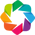

:QuadMesh   [variable,timepoint]   (observed (%))

In [5]:
ep.pl.missing_values_matrix(edata, width=900, height=400)

Drugs and procedures last from a start to an end, and `setup_interval_variables` marks every hour an infusion or a ventilation covers (`keep_date="interval"`). It selects by concept ID and names its variables by position. Like `setup_variables`, it returns an object with only the variables of the call, so the vasopressors, ventilation, antibiotics and samples come in objects of their own, on the same stays and hours.

`omop_etl` records the vasopressor rate in `sig` of `drug_exposure`. A view over the CDM's `drug_exposure` reads it out as a column `rate` and takes its name. In MIMIC-IV it is in µg/kg/min, the unit of SOFA. `specimen` has no `visit_occurrence_id`, so ehrdata gives a sample to every stay of its person whose window holds it.

In [6]:
con.execute("ALTER VIEW drug_exposure RENAME TO drug_exposure_cdm")
con.execute("""
    CREATE VIEW drug_exposure AS
    SELECT *, TRY_CAST(regexp_extract(sig, '(^|;)rate=([^;]*)', 2) AS DOUBLE) AS rate FROM drug_exposure_cdm
""")
VASOPRESSORS = {"norepinephrine": 1321341, "epinephrine": 1343916, "dopamine": 1337860, "dobutamine": 1337720}
vasopressors = ed.io.omop.setup_interval_variables(
    edata,
    data_tables="drug_exposure",
    data_field_to_keep="rate",
    concept_ids=list(VASOPRESSORS.values()),
    aggregation_strategy="max",
    keep_date="interval",
    **grid,
)
names = {concept: name for name, concept in VASOPRESSORS.items()}
vasopressors.var_names = [names[concept] for concept in vasopressors.var["data_table_concept_id"]]

ventilation = ed.io.omop.setup_interval_variables(
    edata,
    data_tables="procedure_occurrence",
    data_field_to_keep="is_present",
    concept_ids=[37158404, 4177224],  # invasive mechanical ventilation, non-invasive ventilation
    keep_date="interval",
    **grid,
)

# RxNorm ingredients of the anti-infectives that omop_etl maps (omop_etl/mappings/drug_ingredients.csv). The builder
# selects ricu's source items instead (../abx_sets.py).
ANTIBIOTICS = {
    "amikacin": 1790868, "amoxicillin": 1713332, "ampicillin": 1717327, "azithromycin": 1734104,
    "aztreonam": 1715117, "cefazolin": 1771162, "cefepime": 1748975, "ceftazidime": 1776684,
    "ceftriaxone": 1777806, "cefuroxime": 1778162, "ciprofloxacin": 1797513, "clindamycin": 997881,
    "daptomycin": 1786617, "erythromycin": 1746940, "gentamicin": 45892419, "levofloxacin": 1742253,
    "linezolid": 1736887, "meropenem": 1709170, "metronidazole": 1707164, "piperacillin": 1746114,
    "sulfamethoxazole": 1836430, "vancomycin": 1707687, "acyclovir": 1703687, "caspofungin": 1718054,
    "fluconazole": 1754994, "micafungin": 19018013, "voriconazole": 1714277,
}
antibiotics = ed.io.omop.setup_interval_variables(
    edata,
    data_tables="drug_exposure",
    data_field_to_keep="is_present",
    concept_ids=list(ANTIBIOTICS.values()),
    keep_date="start",
    **grid,
)

samples = ed.io.omop.setup_variables(edata, data_tables="specimen", data_field_to_keep="is_present", **grid)

for name, other in {
    "vasopressors": vasopressors,
    "ventilation": ventilation,
    "antibiotics": antibiotics,
    "samples": samples,
}.items():
    x = other.X
    print(f"{name:13} {x.shape}, {int(np.isfinite(x).sum())} observed cells")

vasopressors  (117, 4, 216), 1808 observed cells
ventilation   (117, 2, 216), 3925 observed cells
antibiotics   (117, 20, 216), 905 observed cells
samples       (117, 1, 216), 350 observed cells


## ICU labels with ehrapy

The ehrapy tools read every input by name, as a variable of `X` or of a 3D layer, or as a key of `obsm` with a value per stay and hour. `tl.mark_events` marks the hours with ventilation, antibiotics or samples, of any of their concepts, and these markers and the vasopressor rates go into `obsm` of `edata`. The tools count windows in timepoints, here hours, and take and give times in `.obs` as positions on the grid, 0 for its first hour: hour `h` from ICU admission is position `h + grid["num_intervals_before"]`, as the grid starts 48 hours before it.

In [7]:
for other, key in ((ventilation, "ventilation"), (antibiotics, "antibiotics"), (samples, "samples")):
    ep.tl.mark_events(other, key_added=key)
    edata.obsm[key] = other.obsm[key]
    print(f"{key:12} in {other.obs[f'{key}_first'].notna().sum()} stays")
for i, name in enumerate(vasopressors.var_names):
    edata.obsm[name] = vasopressors.X[:, i, :]

ventilation  in 64 stays
antibiotics  in 86 stays
samples      in 105 stays


### SOFA

`tl.sofa` scores the six organs at every hour and sums the worst score of each over the last 24 hours. ricu's windows of a day include both ends, 25 hours, which the builder passes as `closed="both"`. It writes the total to `obsm["sofa"]` and the organs to `obsm["sofa_<organ>"]`. The builder feeds it the inputs as ricu prepares them. It takes the worst value of each hour, such as the lowest PaO2 and the highest creatinine, which needs a second `setup_variables` call because a concept can belong to one set per call, and it applies ricu's rules for ventilation, vasopressors and the GCS of sedated patients. Here SOFA reads the hourly medians and the records as they are.

In [8]:
ep.tl.sofa(
    edata,
    pao2="po2",
    fio2="fio2",
    ventilation="ventilation",
    platelets="plt",
    bilirubin="bili",
    mean_arterial_pressure="map",
    dopamine="dopamine",
    dobutamine="dobutamine",
    epinephrine="epinephrine",
    norepinephrine="norepinephrine",
    gcs="gcs",
    creatinine="crea",
    urine="urine",
)
sofa = edata.obsm["sofa"]
print(f"SOFA scored in {np.isfinite(sofa).mean():.0%} of the stay-hours")
print(f"highest SOFA of a stay: median {pd.DataFrame(sofa).max(axis=1).median():.0f}")

SOFA scored in 43% of the stay-hours
highest SOFA of a stay: median 7


### Suspected infection and Sepsis-3

On MIMIC-IV, ricu suspects an infection where antibiotics and a body fluid sample come close in time. `tl.mark_sustained_events` keeps the hours from which antibiotics go on for 72 hours, or until death, without a gap of more than 24 hours. This is YAIB's `abx_cont`. `tl.mark_paired_events` keeps those followed by a sample within 24 hours and the samples followed by them within 72 hours, and writes the position of the first such hour to `obs["suspected_infection_first"]`. `tl.sepsis3` then looks for a rise of the SOFA score by 2 points from 48 hours before to 24 hours after it. The builder reads the antibiotics and samples at all times; here they end with the grid.

In [9]:
death_hour = (edata.obs["death_datetime"] - edata.obs["visit_start_datetime"]).dt.total_seconds() / 3600
edata.obs["death"] = death_hour + grid["num_intervals_before"]  # a position on the grid, which starts 48 hours earlier
ep.tl.mark_sustained_events(edata, "antibiotics", duration=72, max_gap=24, end_key="death", key_added="abx_cont")
ep.tl.mark_paired_events(edata, "abx_cont", "samples", a_to_b=24, b_to_a=72, key_added="suspected_infection")
ep.tl.sepsis3(edata, infection_key="suspected_infection_first")

onset = edata.obs["sepsis3_onset"] - grid["num_intervals_before"]  # hours from ICU admission
print(f"continuous antibiotics: {edata.obs['abx_cont_first'].notna().sum()} stays")
print(f"suspected infection:    {edata.obs['suspected_infection_first'].notna().sum()} stays")
print(
    f"Sepsis-3:               {edata.obs['sepsis3'].sum()} stays, onset before admission in {(onset < 0).sum()}, "
    f"in hours 0-23 in {((onset >= 0) & (onset < 24)).sum()}, later in {(onset >= 24).sum()}"
)

continuous antibiotics: 36 stays
suspected infection:    36 stays
Sepsis-3:               29 stays, onset before admission in 5, in hours 0-23 in 22, later in 2


### KDIGO

`tl.kdigo` stages acute kidney injury at every hour by creatinine, against the lowest value of the last 48 hours and of the last 7 days, and by the urine output per kg over 6, 12 and 24 hours. Its defaults follow the KDIGO guideline. YAIB compares the urine per kg of a whole window with the guideline's hourly rate, a threshold 6 to 24 times lower, and the builder passes that as `urine_criteria`. With the guideline's rates, as here, many more stays reach stage 1 by urine output. The weight is the median of the stay's weights from `pp.summarize_measurements`, and the urine windows start at ICU admission. `tl.mark_events` with `ignore_zero` then gives the first hour at stage 1 or more.

In [10]:
weight = ep.pp.summarize_measurements(edata, var_names=["weight"], statistics=["median"])
edata.obs["weight"] = weight.X[:, 0]
edata.obs["icu_admission"] = grid["num_intervals_before"]  # the position of hour 0
ep.tl.kdigo(edata, creatinine="crea", urine="urine", weight_key="weight", urine_start_key="icu_admission")
for key in ("kdigo", "kdigo_creatinine", "kdigo_urine"):
    ep.tl.mark_events(edata, key, ignore_zero=True, key_added=key.replace("kdigo", "aki"))

highest = pd.DataFrame(edata.obsm["kdigo"]).max(axis=1)
print("highest KDIGO stage of a stay:", highest.value_counts().sort_index().rename(int).to_dict())
for key, what in (("aki", "either"), ("aki_creatinine", "creatinine"), ("aki_urine", "urine output")):
    print(f"stage 1 or more by {what}: {edata.obs[f'{key}_first'].notna().sum()} stays")

highest KDIGO stage of a stay: {0: 25, 1: 25, 2: 37, 3: 30}
stage 1 or more by either: 92 stays
stage 1 or more by creatinine: 40 stays
stage 1 or more by urine output: 87 stays


### The labels of a stay

`pl.timeseries` shows the scores of every hour, from `obsm`, and the events of a stay, whose positions are in `obs`.
The KDIGO stage is shown as the worst stage of the last 24 hours.
Below every stay, a row of ticks marks the hours of every marker: norepinephrine, ventilation, the antibiotics, the continuous antibiotic treatment, the samples and the suspected infection, which needs the two together.
These are the first two stays with both Sepsis-3 and acute kidney injury.

In [11]:
edata.obsm["kdigo_24h"] = pd.DataFrame(edata.obsm["kdigo"].T).rolling(24, min_periods=1).max().to_numpy().T

ep.pl.timeseries(
    edata,
    obs_names=edata.obs_names[edata.obs["sepsis3"].astype(bool) & edata.obs["aki_first"].notna()][:2],
    var_names=[],
    obsm_keys=["sofa", "kdigo_24h"],
    events=["suspected_infection_first", "sepsis3_onset", "aki_first", "death"],
    markers=["norepinephrine", "ventilation", "antibiotics", "abx_cont", "samples", "suspected_infection"],
    time_key="interval_step",
    xlabel="hour from ICU admission",
    ylabel="score",
    width=700,
    height=250,
)

:Layout
   .Overlay.Time_series_for_observation_2 :Overlay
      .Curve.Sofa                      :Curve   [time]   (value,variable)
      .Curve.Kdigo_24h                 :Curve   [time]   (value,variable)
      .Curve.Suspected_infection_first :Curve   [time]   (value,variable)
      .Curve.Sepsis3_onset             :Curve   [time]   (value,variable)
      .Curve.Aki_first                 :Curve   [time]   (value,variable)
   .Overlay.I                             :Overlay
      .Spikes.Norepinephrine      :Spikes   [time]
      .Spikes.Ventilation         :Spikes   [time]
      .Spikes.Antibiotics         :Spikes   [time]
      .Spikes.Abx_cont            :Spikes   [time]
      .Spikes.Samples             :Spikes   [time]
      .Spikes.Suspected_infection :Spikes   [time]
      .Curve.I                    :Curve   [time]   (row)
      .Curve.II                   :Curve   [time]   (row)
      .Curve.III                  :Curve   [time]   (row)
   .Overlay.Time_series_for_observation_4 :Overlay
      .Curve.Sofa                      :Curve   [time]   (value,variable)
      .Curve.Kdigo_24h                 :Curve   [time]   (value,variable)
      .Curve.Suspected_infection_first :Curve   [time]   (value,variable)
      .Curve.Sepsis3_onset             :Curve   [time]   (value,variable)
      .Curve.Aki_first                 :Curve   [time]   (value,variable)
   .Overlay.II                            :Overlay
      .Spikes.Norepinephrine      :Spikes   [time]
      .Spikes.Ventilation         :Spikes   [time]
      .Spikes.Antibiotics         :Spikes   [time]
      .Spikes.Abx_cont            :Spikes   [time]
      .Spikes.Samples             :Spikes   [time]
      .Spikes.Suspected_infection :Spikes   [time]
      .Curve.I                    :Curve   [time]   (row)
      .Curve.II                   :Curve   [time]   (row)
      .Curve.III                  :Curve   [time]   (row)

## Predicting acute kidney injury

The task: from the first 24 hours of the 48 dynamic variables, predict whether acute kidney injury, KDIGO stage 1 or more, begins later in the first week, among the stays without it before hour 24. Sepsis after hour 24 would be the other label, but the demo has too few such stays. `ep.ml.split` puts every stay into a training, a tuning or a held-out set, and an `ep.ml.Task` names the label and the observation window, as positions on the grid.

In [12]:
aki_hour = edata.obs["aki_first"] - grid["num_intervals_before"]  # hours from ICU admission
# missing for stays with AKI before hour 24
edata.obs["aki_after_24h"] = np.where(aki_hour < 24, np.nan, aki_hour >= 24)
ep.ml.split(edata, stratify="aki_after_24h")
task = ep.ml.Task("aki_after_24h", prediction_time=24 + grid["num_intervals_before"], observation_window=24)
model_variables = YAIB_DYNAMIC_VARS
labeled = edata.obs["aki_after_24h"].notna()
(
    edata.obs[labeled]
    .groupby("split", observed=True)["aki_after_24h"]
    .agg(["size", "sum"])
    .rename(columns={"size": "stays", "sum": "with AKI"})
)

,stays,with AKI
split,,
train,31,13.0
tuning,6,3.0
held_out,7,3.0


`ep.ml.fit` takes any PyTorch module that maps the values, whether they were observed, the time since their last observation and the static covariates to an embedding. We wrap the GRU-D backbone of PyPOTS, which decays missing values towards the mean and its hidden state with the time since the last observation. ehrapy carries the values forward and standardizes them with the training set, so their mean is 0, and gives the time since the last observation as a fraction of the window, which the backbone reads in hours. Its last hidden state is the embedding, as in the GRU-D classifier of PyPOTS. ehrapy then trains it with early stopping on the tuning set and evaluates it on the held-out set.

In [13]:
class GRUD(torch.nn.Module):
    def __init__(self, n_steps: int, n_features: int, hidden_size: int = 32):
        super().__init__()
        self.n_steps = n_steps
        self.backbone = BackboneGRUD(n_steps, n_features, hidden_size)
        self.register_buffer("empirical_mean", torch.zeros(n_features))

    def forward(self, values, mask, time_since_observed, static):
        deltas = time_since_observed * self.n_steps
        return self.backbone(values * mask, mask, deltas, self.empirical_mean, values)[1]


torch.manual_seed(0)
grud = ep.ml.fit(
    edata,
    task,
    model=GRUD(task.observation_window, len(model_variables)),
    var_names=model_variables,
    trainer=ep.ml.Trainer(max_epochs=50, device="cpu"),
)
ep.ml.predict(edata, grud, key_added="grud")
ep.ml.evaluate(edata, task, key="grud", n_bootstrap=200).loc[["auroc", "auprc", "brier"]].round(3)

,value,ci_lower,ci_upper
metric,,,
auroc,0.333,0.000,0.805
auprc,0.443,0.200,0.917
brier,0.269,0.234,0.300


The model predicts the risk at hour 24 from the first 24 hours of a stay.
For the held-out stays with acute kidney injury after hour 24, and the two without it that the model ranks highest, the plot shows the predicted risk next to the creatinine, the KDIGO stage and the onset of acute kidney injury in the first week.

In [14]:
edata.obs["prediction_time"] = task.prediction_time  # a position on the grid, at hour 24
held_out = edata.obs[(edata.obs["split"] == "held_out") & labeled]
shown = pd.concat(
    [held_out[held_out["aki_after_24h"] == 1], held_out[held_out["aki_after_24h"] == 0].nlargest(2, "grud")]
).sort_values("grud", ascending=False)
hv.Layout(
    [
        ep.pl.timeseries(
            edata,
            obs_names=name,
            var_names="crea",
            obsm_keys="kdigo_24h",
            events=["prediction_time", "aki_first"],
            tem_names=slice(task.prediction_time - task.observation_window, None),
            time_key="interval_step",
            xlabel="hour from ICU admission",
            title=f"{name}: predicted risk {stay.grud:.2f}, acute kidney injury after hour 24: {'yes' if stay.aki_after_24h else 'no'}",
            width=700,
            height=200,
        )
        for name, stay in shown.iterrows()
    ]
).cols(1)

:Layout
   .Overlay.A_80_colon_predicted_risk_0_full_stop_59_comma_acute_kidney_injury_after_hour_24_colon_no   :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
   .Overlay.A_103_colon_predicted_risk_0_full_stop_57_comma_acute_kidney_injury_after_hour_24_colon_yes :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)
   .Overlay.A_46_colon_predicted_risk_0_full_stop_55_comma_acute_kidney_injury_after_hour_24_colon_no   :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
   .Overlay.A_81_colon_predicted_risk_0_full_stop_53_comma_acute_kidney_injury_after_hour_24_colon_yes  :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)
   .Overlay.A_27_colon_predicted_risk_0_full_stop_44_comma_acute_kidney_injury_after_hour_24_colon_yes  :Overlay
      .Curve.Crea            :Curve   [time]   (value,variable)
      .Scatter.I             :Scatter   [time]   (value,variable)
      .Curve.Kdigo_24h       :Curve   [time]   (value,variable)
      .Curve.Prediction_time :Curve   [time]   (value,variable)
      .Curve.Aki_first       :Curve   [time]   (value,variable)

With so few stays, the demo is too small for these numbers to mean anything. The hidden cell below fits the same model with PyPOTS alone, on the same split, observation window and standardization.

In [15]:
from pypots.classification import GRUD as PyPOTSGRUD
from pypots.optim import Adam
from pypots.utils.logging import logger
from pypots.utils.random import set_random_seed
from sklearn.metrics import average_precision_score, roc_auc_score

logger.disabled = True  # PyPOTS logs its seed and that no model files are saved
split, y = edata.obs["split"].to_numpy(), edata.obs["aki_after_24h"].to_numpy()
train, tuning, held_out = ((split == name) & ~np.isnan(y) for name in ("train", "tuning", "held_out"))
window = edata[:, model_variables, task.prediction_time - task.observation_window : task.prediction_time].X
X = np.moveaxis(np.asarray(window, dtype=np.float64), 1, 2)  # stays x hours x variables, as PyPOTS takes it
mean, std = np.nanmean(X[train], axis=(0, 1)), np.nanstd(X[train], axis=(0, 1))
X = (X - np.nan_to_num(mean)) / np.where(np.isnan(std) | (std == 0), 1.0, std)

set_random_seed(0)
model = PyPOTSGRUD(
    n_steps=X.shape[1],
    n_features=X.shape[2],
    n_classes=2,
    rnn_hidden_size=32,
    batch_size=128,
    epochs=50,
    patience=10,
    optimizer=Adam(lr=1e-3),
    device="cpu",
    verbose=False,
)
model.fit({"X": X[train], "y": y[train].astype(int)}, {"X": X[tuning], "y": y[tuning].astype(int)})
probability = model.predict({"X": X[held_out]})["classification_proba"][:, 1]
print(
    f"PyPOTS alone: AUROC {roc_auc_score(y[held_out], probability):.3f}, "
    f"AUPRC {average_precision_score(y[held_out], probability):.3f}"
)

PyPOTS alone: AUROC 0.833, AUPRC 0.867


## What the cohort builder adds

The cohort builder (`../build_cohort.py`) runs this path on the MIMIC-IV, eICU and HiRID CDMs and writes YAIB's `dyn`, `sta` and `outc` frames for its five tasks: mortality24, kidney_function, los, aki and sepsis. Beyond this notebook, it

- builds YAIB's base cohort and the exclusions and label windows of each task,
- keeps the variables and label inputs of a build in one sparse `EHRData` and reads label inputs from up to 12 days before admission,
- prepares the label inputs as ricu does: the worst value of an hour, ventilation and vasopressor windows, the GCS of sedated patients, urine rates, antibiotics and samples at all times, and YAIB's KDIGO thresholds,
- and feeds YAIB's training, where its cohorts reproduce the ricu baseline.

`../../RICU.md` lists each ricu rule it follows and where it deliberately differs; the module docstring of `../ehrdata_dynamics.py` describes the one `EHRData` per build.